# Synthèse du groupe 10 : l'histoire complète

Chaque dossier a été analysé dans son propre notebook. Ce notebook ne refait pas ces analyses : il relie leurs résultats, vérifie dans les données les liens entre les dossiers, et reconstitue l'histoire que cachent les données.

*Usage de l'IA générative : ce notebook a été rédigé avec l'aide de Claude (Anthropic), à partir des conclusions des notebooks du groupe. Les liens entre dossiers ont été recalculés ici et les résultats relus. Chaque notebook précise son propre usage de l'IA (partie 5).*

## 1. Les notebooks du dépôt

| Dossier | Notebook(s) | Ce qu'il apporte à l'histoire |
|---|---|---|
| `public_records` | `public_records.ipynb` | les accès de Horizon aux sites naturels, les documents d'enquête, les identités anormales |
| `ecology` | `ecology.ipynb` | la chute des chauves-souris après chaque accès de Horizon |
| `logistics` | `01_nettoyage_logistics.ipynb`, `02_analyse_logistics.ipynb` | les lots biologiques qui disparaissent chez Meridian, les retraits de stock des cliniques Asterion |
| `health` | `01_nettoyage_health.ipynb`, `02_analyse_health.ipynb`, `03_rapport_health.ipynb` | les dirigeants rajeunis par `MRP-42`, les 10 patients au physique non humain |

Les notebooks se lancent depuis la racine du dépôt. Celui-ci lit les données brutes de `public_records`, `ecology` et `health` (seules les dates et quelques nombres sont convertis), et les fichiers logistiques nettoyés par `01_nettoyage_logistics.ipynb`.

In [1]:
import re
import difflib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Registres publics
acces = pd.read_csv("../data/public_records/site_access_case_events.csv")
acces["event_time"] = pd.to_datetime(acces["event_time"], format="mixed")
acces["activity"] = acces["activity"].str.lower()
documents = pd.read_csv("../data/public_records/public_and_investigative_documents.csv").set_index("document_id")
memos = pd.read_csv("../data/public_records/institutional_memos.csv").set_index("document_id")
mandats = pd.read_csv("../data/public_records/officer_filings.csv")
licences = pd.read_csv("../data/public_records/licensed_professionals.csv")
etablissements = pd.read_csv("../data/public_records/licensed_facilities.csv")

# Écologie
chauves = pd.read_csv("../data/ecology/bat_surveys.csv", dtype=str)
climat = pd.read_csv("../data/ecology/environmental_monthly.csv", dtype=str)

# Santé (un patient apparaît deux fois à l'identique : on garde une seule ligne)
patients = pd.read_csv("../data/health/patient_administration.csv").drop_duplicates().set_index("patient_number")
procedures = pd.read_csv("../data/health/clinical_procedures.csv")
procedures["jour"] = pd.to_datetime(procedures["performed_time"], format="mixed").dt.normalize()
observations = pd.read_csv("../data/health/clinical_observations.csv", dtype=str)
notes = pd.read_csv("../data/health/clinical_notes.csv").set_index("document_id")

# Logistique (fichiers nettoyés)
expeditions = pd.read_csv("../data/logistics/clean/shipments_clean.csv", parse_dates=["dispatch_time", "arrival_time"])
ajustements = pd.read_csv("../data/logistics/clean/inventory_adjustments_clean.csv", parse_dates=["adjustment_date"])
stocks = pd.read_csv("../data/logistics/clean/inventory_month_end_clean.csv", parse_dates=["reporting_month"])
sites = pd.read_csv("../data/logistics/clean/erp_facilities_clean.csv").set_index("facility_code")
partenaires = pd.read_csv("../data/logistics/clean/erp_business_partners_clean.csv").set_index("partner_code")


# Renvoie la première phrase d'un texte qui contient un mot donné
def phrase(texte, mot):
    for morceau in re.split(r"(?<=[.!?])\s+|\n+|\s{3,}", texte):
        if mot.lower() in morceau.lower():
            return morceau.strip()


# Convertit une colonne texte en nombres (virgules décimales, unités collées)
def nombre(colonne):
    return pd.to_numeric(colonne.astype(str).str.replace(",", ".").str.extract(r"(-?\d+\.?\d*)")[0], errors="coerce")

## 2. L'histoire, étape par étape

### Étape 1 : des accès de nuit aux grottes, puis une chute des chauves-souris (registres publics → écologie)

In [2]:
# Les dossiers d'accès de Horizon Field Research Cooperative
horizon = acces[acces["requesting_organization_name"] == "Horizon Field Research Cooperative"]
print("Dossiers d'accès de Horizon :", horizon["access_case_number"].nunique(), "sur", acces["access_case_number"].nunique())
print("Sites naturels visités :", horizon["site_code"].nunique(), sorted(horizon["site_code"].unique()))
print("Heure de début :", horizon.loc[horizon["activity"] == "access_started", "event_time"].dt.hour.value_counts().to_dict(),
      "| heure de fin :", horizon.loc[horizon["activity"] == "access_completed", "event_time"].dt.hour.value_counts().to_dict())

Dossiers d'accès de Horizon : 18 sur 60
Sites naturels visités : 8 ['AVL-MAR', 'AVL-ORR', 'AVL-VEL', 'KNT-KES', 'KNT-LUM', 'KNT-SEN', 'TMB-NAC', 'TMB-PEL']
Heure de début : {18: 18} | heure de fin : {3: 18}


In [3]:
# Relevés de chauves-souris : un relevé par site et par mois
chauves["mois"] = pd.to_datetime(chauves["survey_start"], format="mixed").dt.to_period("M")
chauves["nb"] = nombre(chauves["observed_bat_count"])
chauves = chauves.drop_duplicates(["site_code", "mois"])

# Niveau normal : médiane du site pour le même mois de l'année (on retire la saison)
chauves["normal"] = chauves.groupby(["site_code", chauves["mois"].dt.month])["nb"].transform("median")
chauves["ecart_log"] = np.log((chauves["nb"] + 1) / (chauves["normal"] + 1))
releves = chauves.set_index(["site_code", "mois"])["ecart_log"]


# Écart moyen à la normale pendant les 2 mois qui suivent un accès
def apres_acces(site, mois):
    valeurs = [releves.get((site, mois + k)) for k in (1, 2)]
    valeurs = [v for v in valeurs if v is not None and not pd.isna(v)]
    return np.mean(valeurs) if valeurs else np.nan


debuts = acces[acces["activity"] == "access_started"].copy()
debuts["mois"] = debuts["event_time"].dt.to_period("M")
debuts["ecart_apres"] = [apres_acces(s, m) for s, m in zip(debuts["site_code"], debuts["mois"])]
debuts["organisation"] = np.where(debuts["requesting_organization_name"] == "Horizon Field Research Cooperative", "Horizon", "autres")

# Combien d'accès de Horizon sont suivis d'une baisse
baisses = debuts.loc[debuts["organisation"] == "Horizon", "ecart_apres"].dropna()
print("Accès de Horizon suivis d'une baisse :", (baisses < 0).sum(), "sur", len(baisses))

# Variation moyenne du nombre de chauves-souris après les accès, en %
resultat =debuts.dropna(subset=["ecart_apres"]).groupby("organisation")["ecart_apres"].agg(acces="size", ecart_moyen="mean")
resultat["variation_%"] = ((np.exp(resultat["ecart_moyen"]) - 1) * 100).round(0)
resultat

Accès de Horizon suivis d'une baisse : 14 sur 14


,acces,ecart_moyen,variation_%
organisation,,,
Horizon,14,-0.885931,-59.0
autres,26,-0.048680,-5.0


Horizon porte 18 des 60 dossiers d'accès, toujours sur les mêmes 8 sites naturels, et ses accès ont lieu de nuit, de 18 h à 3 h. Dans les deux mois qui suivent **chacun** de ses 14 accès observables, le nombre de chauves-souris baisse par rapport à la normale de saison : **environ 59 % en moyenne**. Après les accès des autres organisations, rien ne change. On retrouve le résultat du notebook `ecology.ipynb` (partie 10), qui le confirme par un test placebo (p ≈ 0,0005) et montre que les autres espèces, les appareils et la météo ne sont pas en cause.

### Étape 2 : un colis réfrigéré 6 h après chaque accès (registres publics → logistique)

In [4]:
# Fin de chaque accès de Horizon
fins = horizon[horizon["activity"] == "access_completed"][["access_case_number", "site_code", "event_time"]]
fins = fins.rename(columns={"event_time": "fin_acces"}).sort_values("fin_acces")

# Les envois « faune » de la logistique
faune = expeditions[expeditions["declared_purpose"] == "environmental and wildlife reference materials"].sort_values("dispatch_time")
print("Envois « faune » :", len(faune), "| expéditeur :", faune["sender_partner_code"].map(partenaires["partner_name"]).unique(),
      "| transporteur :", faune["carrier_partner_code"].map(partenaires["partner_name"]).unique(), "| température :", faune["temperature_control_class"].unique())

# Pour chaque envoi, le dernier accès de Horizon terminé avant le départ
lien = pd.merge_asof(faune, fins, left_on="dispatch_time", right_on="fin_acces", direction="backward")
lien["delai_h"] = (lien["dispatch_time"] - lien["fin_acces"]).dt.total_seconds() / 3600
print("Délai entre la fin de l'accès et le départ (heures) :", lien["delai_h"].value_counts().to_dict(),
      "| dossiers d'accès différents :", lien["access_case_number"].nunique())

# Région du site naturel (3 premières lettres) et entrepôt d'arrivée
pd.crosstab(lien["site_code"].str[:3], lien["destination_facility_code"].map(sites["facility_name"]))

Envois « faune » : 18 | expéditeur : ['Horizon Field Research Cooperative'] | transporteur : ['Northstar Cold Chain Services'] | température : ['2-8C']
Délai entre la fin de l'accès et le départ (heures) : {6.0: 18} | dossiers d'accès différents : 18


destination_facility_code,Meridian Avelora Transfer Annex,Meridian Kintara Biological Aggregation Facility,Meridian Tembara Coastal Hub
site_code,,,
AVL,7,0,0
KNT,0,7,0
TMB,0,0,4


**Les 18 envois « faune » partent tous exactement 6 h après la fin d'un accès de Horizon** (18 sur 18, chaque fois un dossier différent). Horizon les envoie à 2-8 °C par Northstar, un transporteur classé à risque « elevated », vers l'entrepôt Meridian de la même région que le site : Kintara (KNT), Avelora (AVL) ou Tembara (TMB). Les 11 envois d'Avelora et de Tembara sont enregistrés avec l'entrepôt comme départ et comme arrivée : ce sont les « expéditions vers soi-même » de `02_analyse_logistics.ipynb`.

### Étape 3 : les chauves-souris disparaissent chez Meridian (logistique → registres publics)

In [5]:
# Équation des stocks : clôture = ouverture + reçu - sorti - usage interne - déchets
stocks["ecart"] = stocks["closing_stock"] - (stocks["opening_stock"] + stocks["received_quantity"] - stocks["outgoing_quantity"]
                                             - stocks["documented_internal_use"] - stocks["documented_waste"])

# Mois où tout ce qui est reçu ressort aussitôt (« transit »)
transit = stocks[(stocks["received_quantity"] > 0) & (stocks["received_quantity"] == stocks["outgoing_quantity"])]
print("Mois de transit :", len(transit), "| sites :", sorted(transit["facility_code"].unique()), "| catégorie :", transit["item_category"].unique())
print("Lots manquants en moyenne ces mois-là :", round(-transit["ecart"].mean(), 1), "| les autres mois :", round(-stocks.drop(transit.index)["ecart"].mean(), 1))

# Ce qu'en disent les documents internes et d'enquête
for table, numero, mot in [(memos, "MEM-510062", "material sink"), (documents, "PUB-510079", "consumption"), (memos, "MEM-510101", "Unwabu is")]:
    print(f"\n{numero} ({table.loc[numero, 'document_date']}, {table.loc[numero, 'author_name']}) :", phrase(table.loc[numero, "text"], mot))

Mois de transit : 11 | sites : ['FCL-1019', 'FCL-1020'] | catégorie : ['biological_sample']
Lots manquants en moyenne ces mois-là : 8.9 | les autres mois : -0.2

MEM-510062 (2024-04-30, Soren Kade) : This memorandum establishes a material sink in the accounting sequence; it does not identify a destination, user, or purpose.

PUB-510079 (2025-04-09, Mara Venn) : I saw preparation sheets that used the word consumption and matched them to access cases, cold-storage receipts, and adjustment numbers.

MEM-510101 (2025-03-14, Soren Kade) : The chair confirmed that Unwabu is the designation used in the restricted governance schedule for the authority approving CHAMELEO exceptions.


Dans les entrepôts Meridian, des lots biologiques disparaissent des stocks les mois de « transit », quand un colis arrive : c'est la conclusion de `02_analyse_logistics.ipynb`. Les documents disent la même chose avec leurs mots :

- un contrôleur de Meridian (Soren Kade) constate un « puits de matière » dans les comptes des lots biologiques ;
- une lanceuse d'alerte (Mara Venn) explique que ces colis contiennent des *Eonycteris spelaea* vivantes, et qu'au moins une partie sert à la **« consommation »** ;
- les colis sensibles suivent une procédure « CHAMELEO », approuvée par une autorité nommée « Unwabu ».

Reste à savoir **qui consomme** ces chauves-souris.

### Étape 4 : une population qui n'est pas humaine (santé → registres publics)

In [6]:
# Les injections de MRP-42 : dirigeants (accès « restricted_specialist ») et « recherche »
mrp = procedures[procedures["procedure_code"].str.strip().str.upper() == "MRP-42"].copy()
mrp["groupe"] = mrp["authorization_class"].str.lower().map({"restricted_specialist": "dirigeants", "research_restricted": "recherche"})
dirigeants = mrp[mrp["groupe"] == "dirigeants"]
elite = dirigeants["patient_number"].unique()

# Les 10 patients au physique inhabituel repérés dans 03_rapport_health.ipynb (partie 5)
pheno = ["PAT-31037", "PAT-31162", "PAT-31065", "PAT-31233", "PAT-31215", "PAT-31186", "PAT-31115", "PAT-31040", "PAT-31012", "PAT-31086"]
print("Patients à la fois dirigeants et PHENO :", len(set(elite) & set(pheno)))

# Médiane de quelques mesures par patient
observations["code"] = observations["observation_code"].str.upper().str.strip()
observations["valeur"] = nombre(observations["numeric_value"])
mesures = observations.pivot_table(index="patient_number", columns="code", values="valeur", aggfunc="median")
profil = pd.DataFrame({
    "écart pouls cœur - poignet (bpm)": mesures["APICAL"] - mesures["PPULSE"],
    "second pic thoracique": mesures["THORPEAK"],
    "balancement latéral": mesures["LATSWAY"],
    "score d'équilibre": mesures["BALANCE"],
    "reconnaissance caméra": mesures["CAMMATCH"],
    "détection thermique": mesures["THERMQUAL"],
})
groupe = pd.Series("autres patients", index=profil.index)
groupe[pheno] = "PHENO"
groupe[elite] = "dirigeants"
profil.groupby(groupe).median().round(1).T

Patients à la fois dirigeants et PHENO : 0


,PHENO,autres patients,dirigeants
écart pouls cœur - poignet (bpm),23.0,2.0,2.6
second pic thoracique,55.3,24.6,34.0
balancement latéral,61.9,30.0,25.8
score d'équilibre,80.2,76.4,80.4
reconnaissance caméra,73.0,91.6,95.4
détection thermique,76.6,90.4,89.3


In [7]:
# Le document qui nomme cette population, et la note clinique qui relie un patient PHENO à une personne publique
print("PUB-510063 :", phrase(documents.loc["PUB-510063", "text"], "Chamaeleonidian"))
print("\nCLN-510025 (patient", notes.loc["CLN-510025", "patient_number"] + ") :", phrase(notes.loc["CLN-510025", "text"], "Elias Voss"))
print("\nMandat d'Elias Voss :", mandats.loc[mandats["full_name"].str.contains("Elias Voss"), "role_title"].iloc[0])

PUB-510063 : The word Chamaeleonidian appears in a restricted classification note associated with the unusual clinical population.

CLN-510025 (patient PAT-31065) : The patient number can be linked, through non-secret administrative attributes, to the public identity Elias Voss.

Mandat d'Elias Voss : Executive chair of Meridian BioLogistics


Les 10 patients PHENO ont un pouls au cœur bien plus rapide qu'au poignet, un second pic thoracique, une démarche qui tangue sans perte d'équilibre, et ils trompent la caméra et la détection thermique. `03_rapport_health.ipynb` montre en plus, sur leurs ECG, **deux rythmes qui battent séparément** (deux cœurs) et des yeux qui bougent indépendamment. Ce sont des traits de caméléon : un document confidentiel appelle d'ailleurs cette « population clinique inhabituelle » **« Chamaeleonidian »**, un nom d'espèce non humaine.

Ce groupe ne recoupe jamais celui des dirigeants. Et l'un de ces patients (`PAT-31065`) est relié par une note clinique à **Elias Voss, président de Meridian BioLogistics**, l'entreprise où disparaissent les chauves-souris.

### Étape 5 : des identités qui traversent les siècles (registres publics)

In [8]:
# Les dirigeants d'entreprise aux noms récurrents dans les documents historiques
noms_suivis = "Vann|Warden|Vosmere|Voss|Jonah Bell|Julien Marot|Jacob Vale"
mandats[mandats["full_name"].str.contains(noms_suivis)][["full_name", "birth_year_or_age_band", "role_title", "appointment_date", "cessation_date"]].sort_values("appointment_date")

,full_name,birth_year_or_age_band,role_title,appointment_date,cessation_date
0,Edward Vann,1815,Industrial and shipping adviser,1840-01-01,1888-12-31
1,Emil Warden,1871,Commercial and medical investor,1895-01-01,1943-12-31
5,Jonah Bell,1900,Conservation researcher,1924-01-01,1963-12-31
2,Adrian Vosmere,1920–1929,Biotechnology and logistics executive,1952-01-01,1991-12-31
6,Julien Marot,1940–1949,Environmental-policy adviser,1970-01-01,2004-12-31
3,Dr. Elias Voss,1961,Executive chair of Meridian BioLogistics,1996-01-01,NaN
7,Jacob Vale,1971,Founder and senior adviser of Vale Strategy Co...,2008-01-01,NaN


In [9]:
# Licences délivrées il y a plus d'un siècle et toujours actives
anciennes = licences[pd.to_datetime(licences["license_issue_date"], format="mixed") < "1930-01-01"]
for _, lic in anciennes.iterrows():
    nb_acces = acces[acces["authorized_person_name"] == lic["professional_name"]]
    print(f"{lic['professional_name']:12s} licence du {lic['license_issue_date']} ({lic['license_status']}) | accès autorisés depuis 2015 : {len(nb_acces)}")

# Jacob Vale, « né en 1971 », assiste à une réunion de 1962
print("\nPUB-510033 (1962) :", phrase(documents.loc["PUB-510033", "text"], "Present"))
print("PUB-510043 (1942) :", phrase(documents.loc["PUB-510043", "text"], "recur"))

Emil Warden  licence du 1895-07-01 (active) | accès autorisés depuis 2015 : 0
J. Varlan    licence du 1886-07-01 (active) | accès autorisés depuis 2015 : 9
Jonah Bell   licence du 1924-07-01 (active) | accès autorisés depuis 2015 : 9

PUB-510033 (1962) : Present: Jonah Bell, Julien Marot, Jacob Vale, two representatives of the Agricultural Improvement Board, and the secretary.
PUB-510043 (1942) : The Wren Street address, a named associate, and the phrase concerning an “ordinary route” recur in later files associated with Elias Voss.


Les carrières d'Edward Vann (1840-1888), Emil Warden (1895-1943), Adrian Vosmere (1952-1991) et Elias Voss (depuis 1996) **se suivent sans jamais se chevaucher**. Elles partagent la même adresse (Wren Street), les mêmes associés et la même devise : « make the conditions ordinary ». Emil Warden a toujours une licence de médecin active, délivrée en 1895. J. Varlan (licence de 1886) et Jonah Bell (licence de 1924) autorisent encore des accès aux sites naturels entre 2015 et 2025. Jacob Vale, « né en 1971 », assiste à une réunion en 1962.

Ces êtres ne vieillissent pas comme des humains et changent d'identité : c'est cohérent avec l'« identité instable » des patients PHENO à la caméra.

### Étape 6 : le rajeunissement des dirigeants humains (santé → logistique → registres publics)

In [10]:
# Qui sont les 8 dirigeants injectés ?
print(patients.loc[elite, ["given_name", "family_name", "occupation_text"]].to_string())

# Écart entre âge biologique et âge réel, moyenne des 3 dernières mesures de chaque patient
bio = observations[observations["code"] == "BIOAGE"].copy()
bio["date"] = pd.to_datetime(bio["observation_time"], format="mixed")
bio["age_reel"] = (bio["date"] - pd.to_datetime(bio["patient_number"].map(patients["date_of_birth"]), format="mixed")).dt.days / 365.25
bio["ecart_age"] = bio["valeur"] - bio["age_reel"]
ecart_patient = bio.sort_values("date").groupby("patient_number").tail(3).groupby("patient_number")["ecart_age"].mean()
groupe_mrp = mrp.groupby("patient_number")["groupe"].first()
print("\nÂge biologique - âge réel (ans) :", ecart_patient.groupby(ecart_patient.index.map(groupe_mrp).fillna("sans MRP-42")).mean().round(1).to_dict())
print("\nPUB-510045 :", phrase(documents.loc["PUB-510045", "text"], "Eight individuals"))

               given_name family_name                                              occupation_text
patient_number                                                                                    
PAT-31221           Leora      Kassen                       Head of government of Kintara Republic
PAT-31044          Tavian       Serat                    Senior minister of the Avelora Federation
PAT-31174           Mirek      Talven                Regional governor in the Tembara Commonwealth
PAT-31119          Celene       Varro                      Chief executive of Solvane Energy Group
PAT-31074           Oskar      Nivren                 Executive chair of Nivren Maritime Logistics
PAT-31183        Adrienne       Solva                   Executive director of Ardena Capital Union
PAT-31142           Rayan       Belen                               Chair of Belen Agro-Industries
PAT-31099           Elira        Vaun  Retired political intermediary and former council president

Âge biolo

In [11]:
# Les cliniques ont un code FAC dans health et FCL dans logistics : on les relie par leur nom
noms_fac = etablissements.set_index("facility_license_number")["facility_name"]
codes = {fac: sites.index[sites["facility_name"] == nom][0] for fac, nom in noms_fac.items() if (sites["facility_name"] == nom).any()}
mrp["clinique"] = mrp["performing_facility_license"].map(codes)
dirigeants = mrp[mrp["groupe"] == "dirigeants"]

# Les retraits de stock propres aux cliniques Asterion (02_analyse_logistics.ipynb, partie 4)
retraits = ajustements[ajustements["adjustment_reason"].isin(["controlled-area consumption", "procedure stock issue", "specialist programme issue"])]
jours_retrait = set(zip(retraits["facility_code"], retraits["adjustment_date"]))
mrp["retrait_meme_jour"] = [(c, j) in jours_retrait for c, j in zip(mrp["clinique"], mrp["jour"])]
print(mrp.groupby("groupe")["retrait_meme_jour"].agg(injections="size", avec_retrait="sum"))

# Jours entre le départ d'une livraison du siège de Meridian et l'injection, dans la même clinique
livraisons = expeditions[expeditions["declared_purpose"] == "temperature-controlled clinical programme delivery"]
derniere = livraisons[["destination_facility_code", "dispatch_time"]].rename(columns={"destination_facility_code": "clinique"}).sort_values("dispatch_time")
avant = pd.merge_asof(dirigeants.sort_values("jour"), derniere, left_on="jour", right_on="dispatch_time", by="clinique", direction="backward")
print("\nJours entre la livraison et l'injection :", (avant["jour"] - avant["dispatch_time"].dt.normalize()).dt.days.value_counts().to_dict())

            injections  avec_retrait
groupe                              
dirigeants          30            30
recherche           20             0

Jours entre la livraison et l'injection : {8: 26, 331: 1, 127: 1, 513: 1, 344: 1}


Les 8 dirigeants injectés ont un âge biologique **environ 13 ans plus bas** que leur âge réel ; les doses « recherche » n'ont aucun effet. Chaque injection correspond à un retrait de stock le même jour dans la même clinique (30 sur 30), et 26 injections sur 30 ont lieu 8 jours après une livraison réfrigérée du siège de Meridian. Un briefing confidentiel de 2022 décrit exactement ce groupe de 8 personnes.

**Qui sont-ils ?** C'est une interprétation, mais leurs postes correspondent aux leviers dont le circuit a besoin :

- les trois régions des sites naturels : la cheffe du gouvernement de Kintara, un ministre d'Avelora, le gouverneur de Tembara ;
- l'énergie (Solvane), le transport maritime (Nivren), la finance (Ardena), les vergers (Belen) ;
- une intermédiaire politique, Elira Vaun. Elle est déclarée morte en 2021, mais son nom autorise encore des accès aux sites en 2022 et 2024 (`03_rapport_health.ipynb`, partie 7).

Le rajeunissement ressemble donc à **un prix payé à des humains influents pour protéger le circuit**. C'est cohérent avec les registres : 83 % des inspections de routine sont classées sans suite et les mémos sensibles sont restreints (`public_records.ipynb`).

### Étape 7 : deux flux, pas un seul circuit (logistique)

Échantillons biologiques des entrepôts vers le siège : 2
Premier envoi « faune » : 2018-02-16 | première livraison aux cliniques : 2014-07-10


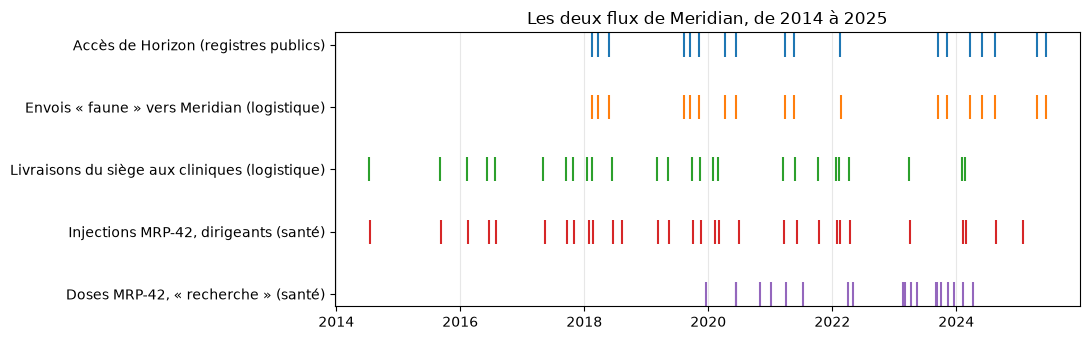

In [12]:
# Échantillons biologiques envoyés des entrepôts Meridian vers le siège
entrepots = ["FCL-1019", "FCL-1020", "FCL-1024"]
vers_siege = expeditions[expeditions["origin_facility_code"].isin(entrepots) & (expeditions["destination_facility_code"] == "FCL-1011")
                         & (expeditions["item_category"] == "biological_sample")]
print("Échantillons biologiques des entrepôts vers le siège :", len(vers_siege))
print("Premier envoi « faune » :", faune["dispatch_time"].min().date(), "| première livraison aux cliniques :", livraisons["dispatch_time"].min().date())

# Une ligne par type d'événement
evenements = {
    "Accès de Horizon (registres publics)": fins["fin_acces"],
    "Envois « faune » vers Meridian (logistique)": faune["dispatch_time"],
    "Livraisons du siège aux cliniques (logistique)": livraisons["dispatch_time"],
    "Injections MRP-42, dirigeants (santé)": dirigeants["jour"],
    "Doses MRP-42, « recherche » (santé)": mrp.loc[mrp["groupe"] == "recherche", "jour"],
}
fig, ax = plt.subplots(figsize=(11, 3.5))
for i, (nom, dates) in enumerate(evenements.items()):
    ax.scatter(dates, [i] * len(dates), marker="|", s=300)
ax.set_yticks(range(len(evenements)))
ax.set_yticklabels(evenements.keys())
ax.invert_yaxis()
ax.grid(axis="x", alpha=0.3)
ax.set_title("Les deux flux de Meridian, de 2014 à 2025")
plt.tight_layout()
plt.show()

Les accès de Horizon et les envois « faune » se superposent exactement (2018-2025). Les livraisons aux cliniques et les injections, elles, commencent **dès 2014, quatre ans avant le premier envoi « faune »**, et presque aucun échantillon ne va des entrepôts au siège. Ce sont donc **deux flux distincts** qui passent par Meridian :

1. les chauves-souris, des grottes vers les entrepôts, où elles disparaissent (« consommation ») ;
2. le produit `MRP-42`, du siège vers les cliniques Asterion, pour les dirigeants.

*Rien ne montre que le MRP-42 est fabriqué à partir des chauves-souris, comme le concluent aussi `02_analyse_logistics.ipynb` et `03_rapport_health.ipynb`.*

### Étape 8 : pourquoi ? Une stratégie de long terme et deux camps (registres publics, écologie)

In [13]:
# La stratégie annoncée en 1962
print("PUB-510033 (1962) :", phrase(documents.loc["PUB-510033", "text"], "warming"))
print("                   ", phrase(documents.loc["PUB-510033", "text"], "objected"))

# Température moyenne des sites par année (2025 est incomplète : seulement janvier à juin)
climat["annee"] = pd.to_datetime(climat["reporting_month"], format="mixed").dt.year
climat["temperature"] = nombre(climat["mean_temperature_c"])
print("\nTempérature moyenne des sites :", climat[climat["annee"] < 2025].groupby("annee")["temperature"].mean().round(2).to_dict())

PUB-510033 (1962) : Bell argued that warming trends and expanded flowering corridors would increase the reliability of nocturnal pollination.
                    Vale objected to the proposed industrial concessions, stating that a programme dependent on extraction and permanent heat increase would eventually destroy the habitat it claimed to support.

Température moyenne des sites : {2019: 26.14, 2020: 26.19, 2021: 26.26, 2022: 26.33, 2023: 26.35, 2024: 26.4}


In [14]:
# Nom public le plus proche de chaque patient PHENO (dirigeants d'entreprise, auteurs de mémos et de documents)
noms_publics = pd.concat([
    mandats[["full_name", "role_title"]].set_axis(["nom", "rôle"], axis=1),
    memos[["author_name", "author_organization"]].set_axis(["nom", "rôle"], axis=1),
    documents[["author_name", "author_organization"]].dropna().set_axis(["nom", "rôle"], axis=1),
]).drop_duplicates("nom")
noms_publics["nom"] = noms_publics["nom"].str.replace("Dr. ", "", regex=False)

lignes = []
for numero in pheno:
    nom_patient = patients.loc[numero, "given_name"] + " " + patients.loc[numero, "family_name"]
    ressemblance = noms_publics["nom"].apply(lambda n: difflib.SequenceMatcher(None, nom_patient.lower(), n.lower()).ratio())
    proche = noms_publics.loc[ressemblance.idxmax()]
    lignes.append({"patient": numero, "nom du patient": nom_patient, "nom public le plus proche": proche["nom"],
                   "rôle ou organisation": proche["rôle"], "ressemblance": round(ressemblance.max(), 2)})
pd.DataFrame(lignes).sort_values("ressemblance", ascending=False)

,patient,nom du patient,nom public le plus proche,rôle ou organisation,ressemblance
9,PAT-31086,Niko Veran,Niko Verran,Cold-chain route-planning manager,0.95
5,PAT-31186,Soren Kader,Soren Kade,Strategic logistics director at Meridian BioLo...,0.95
8,PAT-31012,Amara Sen,Amara Senn,Kintara Cave and Pollinator Authority,0.95
3,PAT-31233,Mara Ven,Mara Venn,Former research-logistics employee and indepen...,0.94
2,PAT-31065,Corin Hallen,Corin Hale,Imaging and physiological-signal specialist,0.91
6,PAT-31115,Nadia Oren,Nadia Aren,Maritime operations executive,0.90
1,PAT-31162,Eli Varen,Olia Aren,Policy consultant,0.78
0,PAT-31037,Sel Aran,Selene Aras,Senior ecological analyst,0.74
7,PAT-31040,Jonah Valen,Jonah Bell,Conservation researcher,0.67
4,PAT-31215,Ilan Roe,Miran Soren,Regional executive,0.63


Dès 1962, un groupe (Jonah Bell, Julien Marot) veut **réchauffer le climat** pour étendre les floraisons nocturnes, et donc les chauves-souris qui les pollinisent, et traiter l'accès aux grottes comme une « infrastructure ». Jacob Vale s'y oppose. La température des sites monte légèrement de 2019 à 2024 (+0,26 °C en 6 ans), un signal faible.

Les deux camps existent toujours : d'un côté Meridian, Northstar et leurs alliés, de l'autre Jacob Vale, le Lantern Investigative Bureau et Threshold Earth (`public_records.ipynb`). Les noms de plusieurs patients PHENO sont presque identiques à ceux de membres **des deux camps** : Soren Kade (Meridian), Niko Verran (Northstar), Nadia Aren (Nivren), Amara Senn (autorité des grottes), mais aussi Mara Venn, la lanceuse d'alerte. Une ressemblance de nom n'est pas une preuve. Les données contiennent d'ailleurs des pièges : `PAT-31065` ressemble à « Corin Hale », alors que la note clinique le relie à Elias Voss par d'autres attributs.

## 3. L'histoire complète

| Étape | Ce qui se passe | Dossier(s) | Ce qui le montre |
|---|---|---|---|
| 1 | Horizon fait 18 accès de nuit à 8 sites naturels ; ensuite, les chauves-souris chutent d'environ 59 % | registres publics + écologie | données, test placebo |
| 2 | 6 h après chaque accès, un colis réfrigéré part vers l'entrepôt Meridian de la région | registres publics + logistique | données, 18 sur 18 |
| 3 | Les lots disparaissent des stocks de Meridian, pour être « consommés » | logistique + registres publics | données et documents |
| 4 | Ceux qui consomment sont une population non humaine (« Chamaeleonidian ») : deux cœurs, yeux indépendants, camouflage ; Elias Voss, président de Meridian, en fait partie | santé + registres publics | données et documents |
| 5 | Ces êtres vivent depuis au moins 1840 sous des identités successives | registres publics | données (licences, mandats) et documents |
| 6 | Ils achètent la protection de 8 dirigeants humains en les rajeunissant avec le MRP-42, livré par Meridian aux cliniques Asterion | santé + logistique + registres publics | données (30 sur 30) ; le « prix de la protection » est une interprétation |
| 7 | Leur stratégie : réchauffer le climat pour avoir plus de chauves-souris ; un camp opposé (Jacob Vale) veut tout révéler | registres publics + écologie | documents ; climat : signal faible |

**En une phrase** : une population non humaine, cachée parmi les humains depuis plus d'un siècle, se nourrit de chauves-souris capturées de nuit dans les grottes et les vergers, les fait passer par l'entreprise de son chef (Meridian), et s'assure le silence des dirigeants humains en les rajeunissant.

## 4. Limites et questions ouvertes

- **Une corrélation n'est pas une causalité** : on montre des coïncidences systématiques (14 sur 14, 18 sur 18, 30 sur 30), pas qui décide.
- **Le contenu du MRP-42 est inconnu.** Rien ne montre qu'il est fabriqué à partir des chauves-souris (étape 7).
- **Les identités et la nature non humaine reposent en partie sur des documents** : chaque document précise lui-même qu'une ressemblance n'est pas une preuve. Les données contiennent aussi des fausses pistes (« CHAMELEO » présenté comme un ancien tableau de bord, « Unwabu » comme un bateau, une capture de chauves-souris « pour baguage »).
- **Restent sans explication** : le lot n° 1 de MRP-42 qui manque, les consultations inventées du 20 juin 2025, et le « non-terrestrial transfer » (toutes les destinations des expéditions existent dans le registre des sites).
- **Peu de cas** (8 dirigeants, 10 patients PHENO, 18 accès) et **données synthétiques** : l'histoire est fictive.

## 5. Usage de l'IA générative

| Notebook | Où | Ce qui est déclaré |
|---|---|---|
| `public_records.ipynb` | dernière cellule | aide ponctuelle à la mise en forme du code et vérification des méthodes du cours |
| `ecology.ipynb` | annexe en fin de notebook | lignes directrices et proposition des étapes d'analyse |
| `02_analyse_logistics.ipynb` | sous le titre | relecture et correction du nettoyage, restructuration et simplification du code |
| `03_rapport_health.ipynb` | première cellule | une grande partie du code et des textes, proposition de méthodes ; choix et validation par l'étudiant |
| `00_synthese.ipynb` | ce notebook | rédaction à partir des conclusions des notebooks ; liens recalculés et relus |